# Question 1: Can weather measurements help predict traffic impact?

**Team question:** Which environmental conditions are associated with accident frequency and traffic-impact severity?

This is a small **modeling baseline** to accompany the [Miami exploration](miami-environment-severity.ipynb). It uses all **500,000 accident records** from the provided CSV. We predict whether a *recorded accident* has `Severity` 3 or 4. In this dataset, severity describes **traffic disruption**, not injuries. The data has no records of trips without accidents, so the model cannot estimate the chance of an accident in different weather.

We compare a model using source, location, and time with a model that also uses weather. That comparison asks whether weather adds predictive information beyond those other recorded factors. It does **not** establish a cause. No outside dataset is used.

## 1. Load the provided data and define the outcome

In [1]:
# Read only the columns needed for this question.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

csv_path = Path('../data/US_Accidents_March23_sampled_500k.csv')
columns = ['Severity', 'Source', 'State', 'Start_Time', 'Weather_Condition',
           'Temperature(F)', 'Humidity(%)', 'Visibility(mi)',
           'Wind_Speed(mph)', 'Precipitation(in)']
accidents = pd.read_csv(csv_path, usecols=columns, low_memory=False)

# Severity 3 or 4 means higher traffic impact. Every row remains in the analysis.
assert len(accidents) == 500_000
assert accidents['Severity'].notna().all()
target = accidents['Severity'].isin([3, 4]).astype(int)
print(f'Accident records: {len(accidents):,}')
print(f'Severity 3–4 records: {target.sum():,} ({target.mean():.1%})')
print('Severity counts:')
display(accidents['Severity'].value_counts().sort_index())

Accident records: 500,000
Severity 3–4 records: 97,584 (19.5%)
Severity counts:


Severity
1      4274
2    398142
3     84520
4     13064
Name: count, dtype: int64

## 2. Prepare the predictors without throwing away rows

`Weather_Condition` stays as its original CSV label. The model groups rare labels automatically, so we do not need to decide yet which labels count as “extreme.” Missing text becomes a **Missing** category. Missing numeric weather readings are filled using the **training data median**, and an extra indicator records which values were missing. This keeps every accident row while letting the model run. It does not mean the filled value is the real weather.

`Source`, `State`, year, and local hour are comparison controls. They help us avoid confusing different data sources or places with weather effects. We do not use `End_Time` or `Distance(mi)`, which could reflect the accident's consequences.

In [2]:
# Extract year and local hour from Start_Time (which is stored in local time).
time_parts = accidents['Start_Time'].astype('string').str.extract(
    r'^(?P<Year>\d{4})-\d{2}-\d{2}[ T](?P<Hour>\d{2})'
)
features = accidents.drop(columns=['Severity', 'Start_Time']).copy()
features['Year'] = pd.to_numeric(time_parts['Year'], errors='coerce')
features['Hour'] = pd.to_numeric(time_parts['Hour'], errors='coerce')

weather_numbers = ['Temperature(F)', 'Humidity(%)', 'Visibility(mi)',
                   'Wind_Speed(mph)', 'Precipitation(in)']
for column in weather_numbers:
    features[column] = pd.to_numeric(features[column], errors='coerce')

print('Missing values in the model inputs:')
display(features.isna().sum().sort_values(ascending=False))
assert len(features) == len(target) == 500_000

Missing values in the model inputs:


Precipitation(in)    142616
Wind_Speed(mph)       36987
Visibility(mi)        11291
Humidity(%)           11130
Weather_Condition     11101
Temperature(F)        10466
State                     0
Source                    0
Year                      0
Hour                      0
dtype: int64

## 3. Train two simple models on the same rows

The **controls-only** model uses source, state, year, and hour. The **controls + weather** model adds the weather label and numeric measurements. We reserve 20% of rows for testing. The split preserves the share of higher-impact accidents in both parts. All filling and scaling are learned from the training rows only.

In [3]:
# One split is reused for both models so their scores are comparable.
train_rows, test_rows = train_test_split(
    np.arange(len(features)), test_size=0.20, random_state=42, stratify=target
)

def make_model(include_weather):
    numeric_columns = ['Year', 'Hour'] + (weather_numbers if include_weather else [])
    category_columns = ['Source', 'State'] + (['Weather_Condition'] if include_weather else [])
    numeric_steps = Pipeline([
        ('fill', SimpleImputer(strategy='median', add_indicator=True)),
        ('scale', StandardScaler()),
    ])
    category_steps = Pipeline([
        ('fill', SimpleImputer(strategy='constant', fill_value='Missing')),
        ('encode', OneHotEncoder(handle_unknown='ignore', min_frequency=100)),
    ])
    prepare = ColumnTransformer([
        ('numbers', numeric_steps, numeric_columns),
        ('categories', category_steps, category_columns),
    ])
    return Pipeline([
        ('prepare', prepare),
        ('model', LogisticRegression(max_iter=300, tol=0.001)),
    ])

models = {}
predictions = {}
for name, use_weather in [('Controls only', False), ('Controls + weather', True)]:
    model = make_model(use_weather)
    model.fit(features.iloc[train_rows], target.iloc[train_rows])
    models[name] = model
    predictions[name] = model.predict_proba(features.iloc[test_rows])[:, 1]
    print(f'Trained: {name}')

print(f'Training rows: {len(train_rows):,}; test rows: {len(test_rows):,}')

Trained: Controls only
Trained: Controls + weather
Training rows: 400,000; test rows: 100,000


In [4]:
#gather (get it from already model and get features to match)
weather_model = models['Controls + weather']
preprocessor = weather_model.named_steps['prepare']
regression = weather_model.named_steps['model']
feature_names = preprocessor.get_feature_names_out()
coefficients = regression.coef_[0]

# make table with coefficients and odds ratios
coefficient_table = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Odds Ratio': np.exp(coefficients)
})

# show the top 10 pos/neg coefficients
print("Largest positive coefficients:")
display(coefficient_table.sort_values(
    'Coefficient', ascending=False
).head(10))

print("Largest negative coefficients:")
display(coefficient_table.sort_values(
    'Coefficient', ascending=True
).head(10))

Largest positive coefficients:


,Feature,Coefficient,Odds Ratio
19,categories__State_CO,1.000126,2.718625
37,categories__State_MO,0.989923,2.691028
24,categories__State_GA,0.980954,2.666999
20,categories__State_CT,0.661634,1.937956
33,categories__State_MD,0.657295,1.929565
59,categories__State_WI,0.573084,1.773728
28,categories__State_IN,0.562976,1.755890
27,categories__State_IL,0.542661,1.720579
14,categories__Source_Source3,0.413628,1.512294
30,categories__State_KY,0.366551,1.442750


Largest negative coefficients:


,Feature,Coefficient,Odds Ratio
49,categories__State_OK,-1.493813,0.224515
12,categories__Source_Source1,-1.337054,0.262618
40,categories__State_NC,-1.091705,0.335644
53,categories__State_SC,-1.041417,0.352954
31,categories__State_LA,-0.879561,0.414965
17,categories__State_AZ,-0.782748,0.457148
42,categories__State_NE,-0.614939,0.540674
50,categories__State_OR,-0.612539,0.541973
51,categories__State_PA,-0.450740,0.637157
23,categories__State_FL,-0.432370,0.648969


Our question is unanswered so far.  We are mainly looking at state and data-source variables. We need to examine the coefficients for temperature, precipitation, visibility, humidity, wind speed, and weather conditions.

In [5]:
#gather
weather_terms = [
    'Temperature', 'Humidity', 'Visibility',
    'Wind_Speed', 'Precipitation', 'Weather_Condition'
]

#filter
weather_results = coefficient_table[
    coefficient_table['Feature'].str.contains(
        '|'.join(weather_terms), regex=True
    )
].copy()

#sort (by coeff.)
weather_results = weather_results.sort_values(
    'Coefficient', ascending=False
)

#show
display(weather_results)

,Feature,Coefficient,Odds Ratio
93,categories__Weather_Condition_Rain,0.199096,1.220299
72,categories__Weather_Condition_Heavy Rain,0.114874,1.121732
99,categories__Weather_Condition_T-Storm,0.078781,1.081967
98,categories__Weather_Condition_Snow,0.057194,1.058861
80,categories__Weather_Condition_Light Rain with ...,0.053969,1.055452
83,categories__Weather_Condition_Light Thundersto...,0.053380,1.054831
2,numbers__Temperature(F),0.047062,1.048187
5,numbers__Wind_Speed(mph),0.035687,1.036332
78,categories__Weather_Condition_Light Rain,0.027238,1.027612
66,categories__Weather_Condition_Drizzle,0.026731,1.027092


### Weather Interpretaion

I used Kevin's logistic regression model to look at the coefficients and odds ratios for the environmental variables. The results show that some weather conditions (including rain and heavy rain) have positive coefficients/ On the other hand, fair weather and fog have negative coefficients. Temperature, wind speed, visibility, precipitation, and humidity also have positive coefficients, but most were relatively small.

Since the numerical variables were standardized, their odds ratios represent changes per standard deviation. The weather categories need to be compared with each other rather than interpreting their individual odds ratios as comparisons against a baseline.

Overall, the model suggests some associations between environmental conditions and higher traffic-impact severity. However, these results do NOT prove causation and the earlier model comparison showed that adding weather provided very little improvement in predictive performance.

## 4. Compare results on the held-out rows

**Average precision** summarizes how well the model puts higher-impact accidents near the top of its predictions. A no-skill baseline scores about the share of severity 3–4 records. **ROC AUC** is another ranking score; 0.5 is the no-skill level. These scores are more useful here than overall accuracy because severity levels are imbalanced.

In [6]:
# Evaluate both models using the same untouched test rows.
test_target = target.iloc[test_rows]
results = pd.DataFrame([
    {
        'Model': name,
        'Average precision': average_precision_score(test_target, scores),
        'ROC AUC': roc_auc_score(test_target, scores),
    }
    for name, scores in predictions.items()
]).set_index('Model')
display(results.round(3))
print(f'No-skill average precision: {test_target.mean():.3f}')
print(f'Test-set severity 3–4: {test_target.sum():,} / {len(test_target):,}')

,Average precision,ROC AUC
Model,,
Controls only,0.414,0.783
Controls + weather,0.415,0.784


No-skill average precision: 0.195
Test-set severity 3–4: 19,517 / 100,000


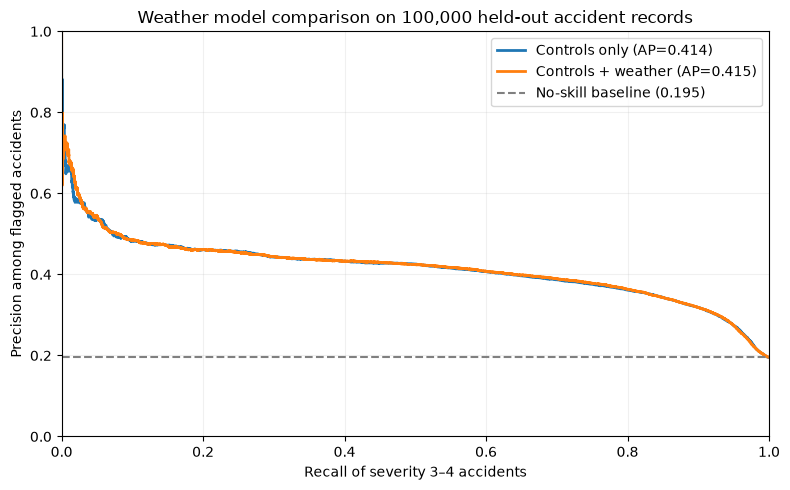

Saved: ../charts/q1_weather_model_precision_recall.png


In [7]:
# A precision–recall curve shows the tradeoff as the cutoff changes.
fig, ax = plt.subplots(figsize=(8, 5))
for name, scores in predictions.items():
    precision, recall, _ = precision_recall_curve(test_target, scores)
    ap = average_precision_score(test_target, scores)
    ax.plot(recall, precision, label=f'{name} (AP={ap:.3f})', linewidth=2)
ax.axhline(test_target.mean(), color='gray', linestyle='--',
           label=f'No-skill baseline ({test_target.mean():.3f})')
ax.set(xlabel='Recall of severity 3–4 accidents',
       ylabel='Precision among flagged accidents',
       title='Weather model comparison on 100,000 held-out accident records',
       xlim=(0, 1), ylim=(0, 1))
ax.grid(alpha=0.18)
ax.legend(loc='upper right')
fig.tight_layout()
chart_path = Path('../charts/q1_weather_model_precision_recall.png')
chart_path.parent.mkdir(exist_ok=True)
fig.savefig(chart_path, dpi=180, bbox_inches='tight')
plt.show()
print('Saved:', chart_path)

## 5. What this model can and cannot say

- On the 100,000 test accidents, average precision was **0.414 with controls only** and **0.415 after adding weather**. ROC AUC was **0.783** and **0.784**, respectively. The gain is very small for this simple model and split.
- This does **not** prove weather is unimportant. It means these weather fields added little predictive information beyond source, state, year, and hour in this particular test. The Miami notebook shows the weather and severity counts directly.
- A higher model score would mean **association and predictive value**, not that weather caused the accident or its traffic impact.
- We modeled only accidents already in the CSV. Without traffic volume and non-accident trips, we cannot estimate accident frequency *risk* under each weather condition.
- The CSV is a 500,000-row sample with an unknown selection method. The random split checks performance within this sample, not a future year or another city.
- The full data remains intact. Missing values are kept visible in the check above and handled inside each model, never silently treated as real observations.
- These results are a **baseline for team review**. The team should agree on the final weather grouping and evaluate source-specific behavior before presenting a stronger conclusion.